In [ ]:
from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist
import numpy as np
import pickle as pkl
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Demostración: K-Means clustering

Nota: Ejemplo adaptado de "Hands on Machine Learning" de Geron Aurelien.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

Creemos un data set sintético para demostrar el algoritmo de K-Means usando la función make_blobs de Scikit-Learn.

(2000, 2)


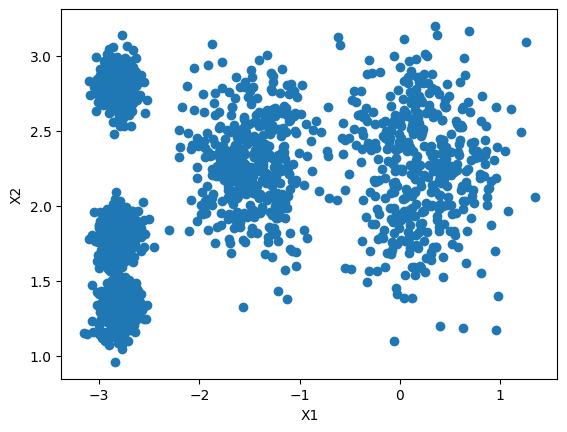

In [ ]:
# Los centros de nuestors grupos, k=5
blob_centers = np.array([
    [ 0.2,  2.3],
    [-1.5 ,  2.3],
    [-2.8,  1.8],
    [-2.8,  2.8],
    [-2.8,  1.3]
])

# El "tamaño" de cada grupo (desviación estándar)
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

X, y = make_blobs(
    n_samples=2000,
    centers=blob_centers,
    cluster_std=blob_std,
    random_state=7
)

print(X.shape)
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel('X1')
plt.ylabel('X2');

Ahora, creamos una instancia de la clase, sabemos que queremos 5 grupos, aunque no siempre estaremos seguros.

In [ ]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=1, n_init='auto')
kmeans.fit(X)

y_pred = kmeans.predict(X)
# Esta información también se encuentra en KMeans().labels_
# ¿Para qué más podemos usar predict entonces?
y_pred

array([1, 4, 0, ..., 3, 0, 4], dtype=int32)

Los centroides estan almacenados en:

In [ ]:
centroids = kmeans.cluster_centers_
centroids

array([[ 0.20876306,  2.25551336],
       [-2.80037642,  1.30082566],
       [-1.46679593,  2.28585348],
       [-2.79290307,  2.79641063],
       [-2.80389616,  1.80117999]])

Miremos la asignación de grupos.

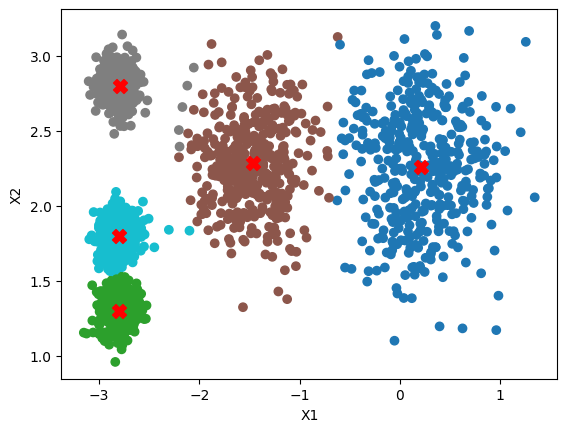

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10')
plt.scatter(centroids[:, 0], centroids[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');

Podemos predecir el grupo de nuevas observaciones. Ojo, no se recalculan los centroides.

In [ ]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([0, 0, 3, 3], dtype=int32)

La distancia a los centroides se puede obtener con el método `transform`. Esto es similar a un "soft clustering".

In [ ]:
kmeans.transform(X_new).round(2)

array([[0.33, 2.89, 1.49, 2.9 , 2.81],
       [2.8 , 5.84, 4.48, 5.85, 5.81],
       [3.29, 1.71, 1.69, 0.29, 1.21],
       [3.22, 1.22, 1.55, 0.36, 0.73]])

Recordemos que durante la presentación discutimos acerda de la incialización del algoritmo y como una mala incialización puede llevar a un resultado sub-optimo. En Scikit-Learn podemos controlar este comportamiento con los parámetros `n_init` y `init`.
Con inicialización aleatoria es necesario repetir varia veces el algoritmo para encontrar una buena partición.

K-mean++ es una forma de inicializar el algoritmo K-means de una manera más inteligente, para mantener los puntos de inicialización alejados entre sí.
Para realizar la inicialización, primero elige un centroide inicial al azar entre las observaciones en 𝑋. Luego, para los centroides restantes, elige el siguiente centroide entre los puntos restantes en 𝑋 con probabilidad proporcional a la distancia al cuadrado desde el centroide más cercano.

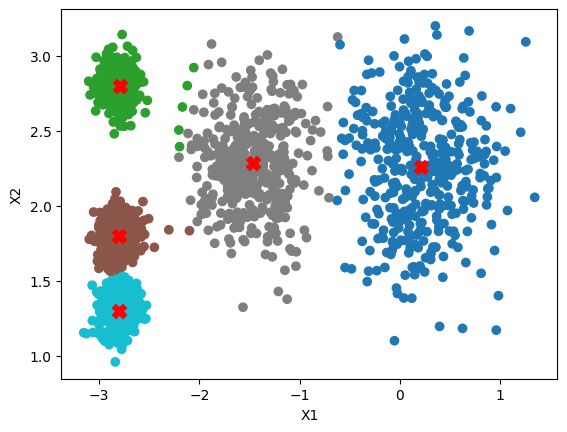

In [ ]:
# Probemos diferentes combinaciones de n_init e init
# kmeans = KMeans(n_clusters=k, init='random', n_init=1)
kmeans = KMeans(n_clusters=k, init='k-means++', n_init=100)
y_pred = kmeans.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10')
plt.scatter(centroids[:, 0], centroids[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');

También es posibles especificar la posición inicial de los centroides.

Para seleccionar el mejor modelo, necesitaremos una forma de evaluar su rendimiento. Desafortunadamente, la agrupación es una tarea no supervisada, por lo que no tenemos las etiquetas. Pero podemos medir la distancia entre cada instancia y su centroide. A la suma de las distancias cuadradas a su centroide asignado se le llama inercia. De hecho, cuando ejecutamos KMeans con diferentes inicializaciones, el agoritmo elige la de menor inercia.

La inercia siempre disminuye con el número de grupos (k), pero podemos evaluar su tasa de cambio para encontrar el punto de inflexión. A este método se le conoce como el método del codo.

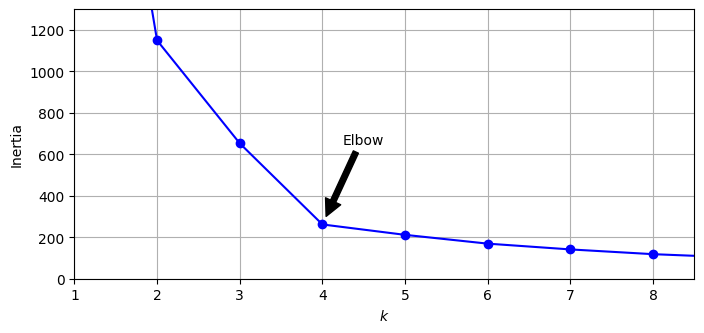

In [ ]:
kmeans_per_k = [KMeans(n_clusters=k, n_init=10, init='k-means++').fit(X)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate("", xy=(4, inertias[3]), xytext=(4.45, 650),
             arrowprops=dict(facecolor='black', shrink=0.1))
plt.text(4.5, 650, "Elbow", horizontalalignment="center")
plt.axis([1, 8.5, 0, 1300])
plt.grid();

Parece que 4 grupos es una buena opción, aunque combina los grupos más pequeños.

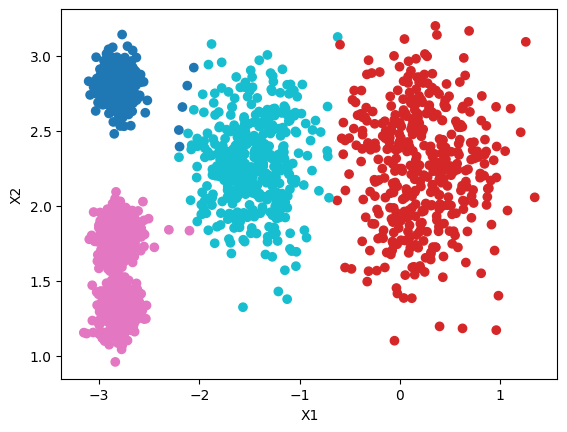

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=kmeans_per_k[3].labels_, cmap='tab10')
plt.xlabel('X1')
plt.ylabel('X2');

Otro enfoque es observar la puntuación de silueta, que es el coeficiente de silueta medio sobre todas las obervaciones. El coeficiente de silueta de una instancia es igual a $(b - a) / \max(a, b)$ donde $a$ es la distancia media a las otras instancias del mismo grupo y $b$ es la distancia media a las instancias del siguiente clúster más cercano (definido como el que minimiza $b$, excluyendo el propio clúster de la instancia). El coeficiente de silueta puede variar entre -1 y +1: un coeficiente cercano a +1 significa que la instancia está dentro de su propio grupo y lejos de otros grupos, mientras que un coeficiente cercano a 0 significa que está cerca del límite de un grupo. y finalmente un coeficiente cercano a -1 significa que es posible que la instancia haya sido asignada al clúster incorrecto.

In [ ]:
from sklearn.metrics import silhouette_score

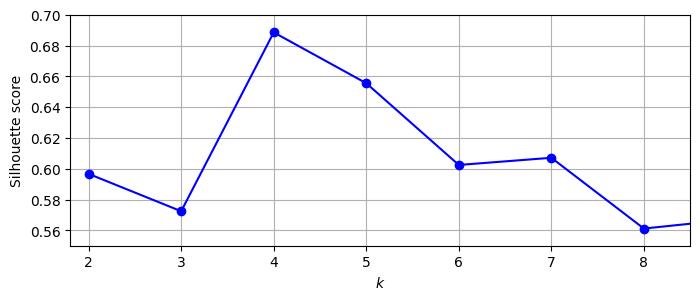

In [ ]:
silhouette_scores = [
    silhouette_score(X, model.labels_)
    for model in kmeans_per_k[1:]
]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.axis([1.8, 8.5, 0.55, 0.7])
plt.grid();

Como puede ver, esta visualización es mucho más rica que la anterior: en particular, aunque confirma que $k=4$ es una muy buena elección, también subraya el hecho de que $k=5$ también es bastante buena.

Se obtiene una visualización aún más informativa cuando se traza el coeficiente de silueta de cada instancia, ordenado por el grupo al que están asignados y por el valor del coeficiente. Esto se llama diagrama de silueta:

In [ ]:
from yellowbrick.cluster import silhouette_visualizer

In [ ]:
kmeans_per_k[2:6]

[KMeans(n_clusters=3, n_init=10),
 KMeans(n_clusters=4, n_init=10),
 KMeans(n_clusters=5, n_init=10),
 KMeans(n_clusters=6, n_init=10)]

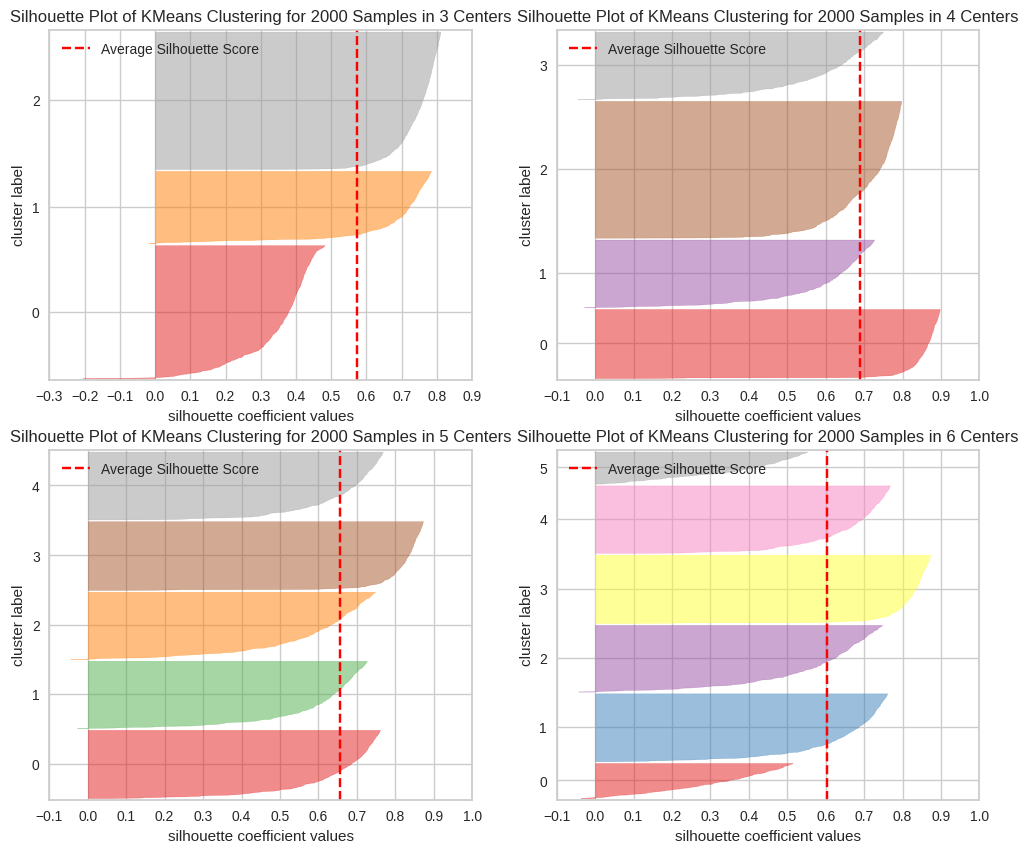

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

visualizers = [silhouette_visualizer(model, X, ax=ax, show=False) for model, ax in zip(kmeans_per_k[2:6], axes)]

Como puede ver, $k=5$ parece la mejor opción aquí, ya que todos los grupos son aproximadamente del mismo tamaño y todos cruzan la línea discontinua, que representa la puntuación media de la silueta.

Sin embargo, K-Means asume grupos esféricos, e intenta encontrar este tipo de grupos. Veamos que pasa si esta suposición no es correcta.

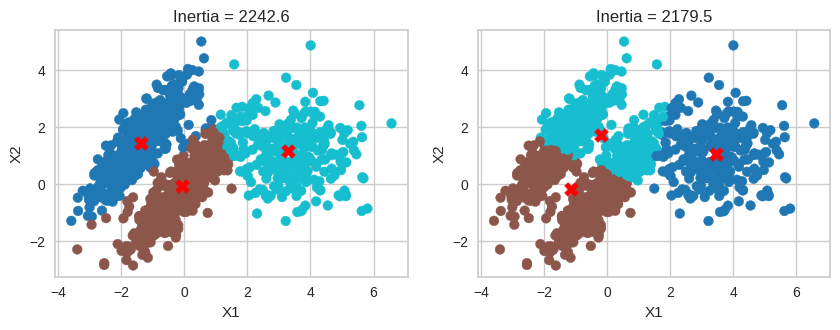

In [ ]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

kmeans_good = KMeans(n_clusters=3,
                     init=np.array([[-1.5, 2.5], [0.5, 0], [4, 0]]),
                     n_init=1, random_state=42)
kmeans_bad = KMeans(n_clusters=3, random_state=42, n_init=100, init='k-means++')

kmeans_good.fit(X)
kmeans_bad.fit(X)

plt.figure(figsize=(10, 3.2))

plt.subplot(121)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_good.labels_, cmap='tab10')
plt.scatter(kmeans_good.cluster_centers_[:, 0], kmeans_good.cluster_centers_[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');
plt.title(f"Inertia = {kmeans_good.inertia_:.1f}")

plt.subplot(122)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_bad.labels_, cmap='tab10')
plt.scatter(kmeans_bad.cluster_centers_[:, 0], kmeans_bad.cluster_centers_[:, 1], color='red', marker='X', s=100)
plt.xlabel('X1')
plt.ylabel('X2');
plt.title(f"Inertia = {kmeans_bad.inertia_:.1f}");